In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
sc.settings.verbosity = 3
sc.logging.print_header()

scanpy==1.9.3 anndata==0.8.0 umap==0.5.3 numpy==1.23.5 scipy==1.10.1 pandas==1.5.3 scikit-learn==1.2.1 statsmodels==0.13.5 python-igraph==0.10.1 louvain==0.7.1 pynndescent==0.5.8


In [2]:
SAMPLES = {
    "adata1":  ("/home/julia/data/placodes/ANDY/E9_003_mapped/outs/filtered_feature_bc_matrix.h5",  "E9",  "E9_L003"),
    "adata2":  ("/home/julia/data/placodes/ANDY/E9_004_mapped/outs/filtered_feature_bc_matrix.h5",  "E9",  "E9_L004"),
    "adata3":  ("/home/julia/data/placodes/ANDY/E9_005_mapped/outs/filtered_feature_bc_matrix.h5",  "E9",  "E9_L005"),
    "adata4":  ("/home/julia/data/placodes/ANDY/E9_006_mapped/outs/filtered_feature_bc_matrix.h5",  "E9",  "E9_L006"),

    "adata5":  ("/home/julia/data/placodes/ANDY/E10_L003_mapped/outs/filtered_feature_bc_matrix.h5", "E10", "E10_L003"),
    "adata6":  ("/home/julia/data/placodes/ANDY/E10_L004_mapped/outs/filtered_feature_bc_matrix.h5", "E10", "E10_L004"),
    "adata7":  ("/home/julia/data/placodes/ANDY/E10_L005_mapped/outs/filtered_feature_bc_matrix.h5", "E10", "E10_L005"),
    "adata8":  ("/home/julia/data/placodes/ANDY/E10_L006_mapped/outs/filtered_feature_bc_matrix.h5", "E10", "E10_L006"),

    "adata9":  ("/home/julia/data/placodes/ANDY/E11_L003_mapped/outs/filtered_feature_bc_matrix.h5", "E11", "E11_L003"),
    "adata10": ("/home/julia/data/placodes/ANDY/E11_L004_mapped/outs/filtered_feature_bc_matrix.h5", "E11", "E11_L004"),
    "adata11": ("/home/julia/data/placodes/ANDY/E11_L005_mapped/outs/filtered_feature_bc_matrix.h5", "E11", "E11_L005"),
    "adata12": ("/home/julia/data/placodes/ANDY/E11_L006_mapped/outs/filtered_feature_bc_matrix.h5", "E11", "E11_L006"),
}

len(SAMPLES)


12

In [3]:
sample_objects = {}

for name, (path, day, plate) in SAMPLES.items():
    a = sc.read_10x_h5(path)
    a.var_names_make_unique()

    a.obs["day"] = day
    a.obs["plate"] = plate

    sample_objects[name] = a
    globals()[name] = a

    print(f"{name:>7} | {plate:>8} | {day:>3} | {a.n_obs:>7} cells | {a.n_vars:>6} genes")


reading /home/julia/data/placodes/ANDY/E9_003_mapped/outs/filtered_feature_bc_matrix.h5
 (0:00:00)
 adata1 |  E9_L003 |  E9 |    4377 cells |  32285 genes
reading /home/julia/data/placodes/ANDY/E9_004_mapped/outs/filtered_feature_bc_matrix.h5


/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


 (0:00:00)
 adata2 |  E9_L004 |  E9 |    4387 cells |  32285 genes
reading /home/julia/data/placodes/ANDY/E9_005_mapped/outs/filtered_feature_bc_matrix.h5


/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


 (0:00:00)
 adata3 |  E9_L005 |  E9 |    4395 cells |  32285 genes
reading /home/julia/data/placodes/ANDY/E9_006_mapped/outs/filtered_feature_bc_matrix.h5


/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


... (14 outputs left out)

 (0:00:00)
adata11 | E11_L005 | E11 |    6108 cells |  32285 genes
reading /home/julia/data/placodes/ANDY/E11_L006_mapped/outs/filtered_feature_bc_matrix.h5


/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


 (0:00:00)
adata12 | E11_L006 | E11 |    6082 cells |  32285 genes


/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [4]:
adata = sc.concat(
    sample_objects,
    label="sample_id",
    join="outer",
    index_unique="-",
    merge="same",
    fill_value=0
)

In [5]:
adata.obs["day"] = adata.obs["day"].astype("category")
adata.obs["plate"] = adata.obs["plate"].astype("category")

print(adata)
print("Unique cell names:", adata.obs_names.is_unique)

display(
    adata.obs.groupby(["day", "plate"], observed=True)
    .size()
    .rename("n_cells")
    .to_frame()
)


AnnData object with n_obs × n_vars = 104287 × 32285
    obs: 'day', 'plate', 'sample_id'
    var: 'gene_ids', 'feature_types', 'genome'
Unique cell names: True


n_cells
day plate            
E9  E9_L003      4377
    E9_L004      4387
    E9_L005      4395
    E9_L006      4382
E10 E10_L003    15602
    E10_L004    15584
    E10_L005    15582
    E10_L006    15585
E11 E11_L003     6095
    E11_L004     6108
    E11_L005     6108
    E11_L006     6082

In [6]:
adata.var["mt"] = adata.var_names.str.startswith("mt-")

sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True
)

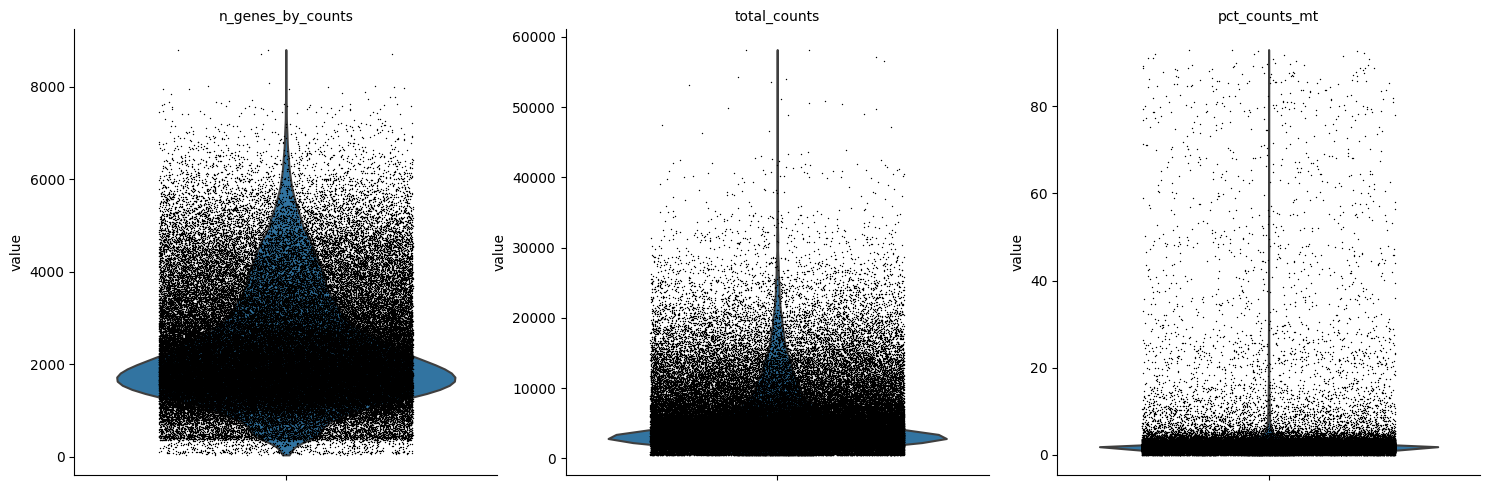

In [7]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], jitter=0.3, multi_panel=True)

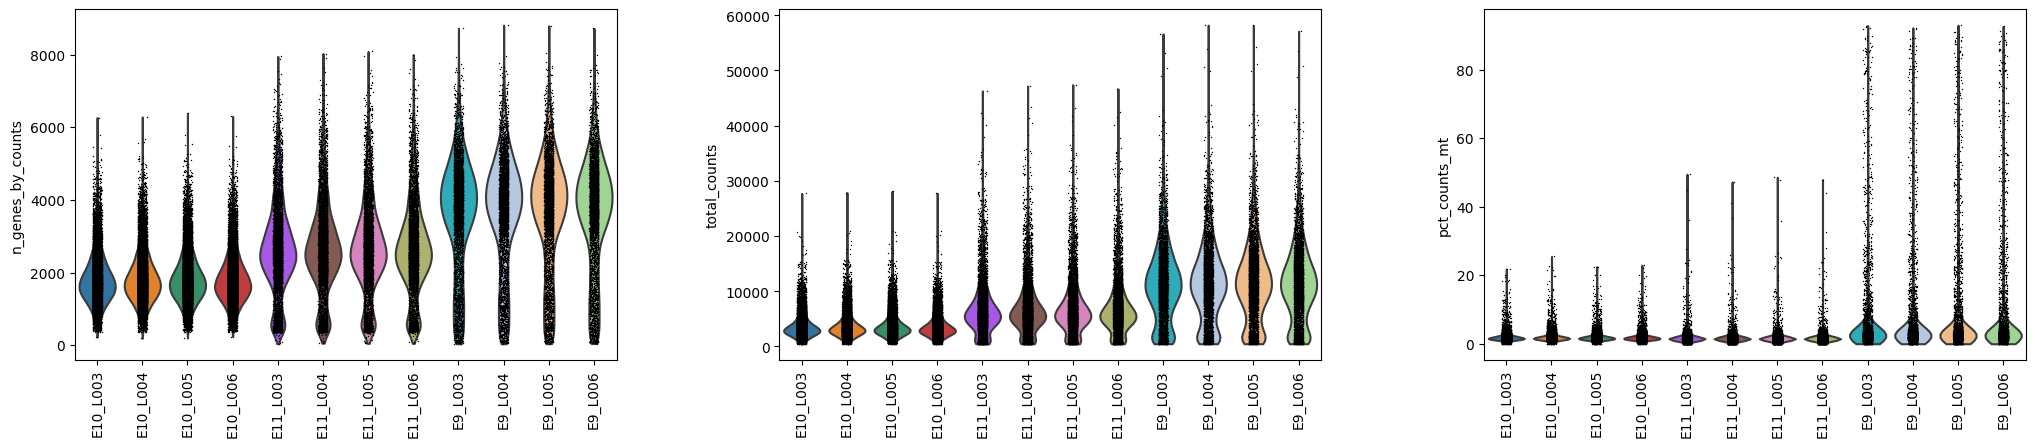

In [8]:
sc.pl.violin( adata,  ["n_genes_by_counts", "total_counts", "pct_counts_mt"], groupby="plate", rotation=90, multi_panel=True)

In [9]:
adata = adata[
    (adata.obs["n_genes_by_counts"] > 800) &
    (adata.obs["pct_counts_mt"] < 10)
].copy()

In [10]:
scrubbed = []

for plate in adata.obs["plate"].unique():
    print(f"\nRunning Scrublet: {plate}")

    x = adata[adata.obs["plate"] == plate].copy()

    sc.external.pp.scrublet(x)

    print(
        f"{x.n_obs} cells | "
        f"{x.obs['predicted_doublet'].sum()} predicted doublets | "
        f"{100*x.obs['predicted_doublet'].mean():.2f}%"
    )

    scrubbed.append(x)


Running Scrublet: E9_L003
Running Scrublet
filtered out 12534 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell


/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/scanpy/preprocessing/_normalization.py:170: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


    finished (0:00:00)
Embedding transcriptomes using PCA...
Automatically set threshold at doublet score = 0.50
Detected doublet rate = 0.2%
Estimated detectable doublet fraction = 8.3%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 2.8%
    Scrublet finished (0:00:07)
3881 cells | 9 predicted doublets | 0.23%

Running Scrublet: E9_L004
Running Scrublet
filtered out 12523 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell


/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/scanpy/preprocessing/_normalization.py:170: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


    finished (0:00:00)
Embedding transcriptomes using PCA...
Automatically set threshold at doublet score = 0.50
Detected doublet rate = 0.2%
Estimated detectable doublet fraction = 7.3%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 2.5%
    Scrublet finished (0:00:08)
3877 cells | 7 predicted doublets | 0.18%

Running Scrublet: E9_L005
Running Scrublet
filtered out 12515 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell


/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/scanpy/preprocessing/_normalization.py:170: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


... (15 outputs left out)

/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/scanpy/preprocessing/_normalization.py:170: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Embedding transcriptomes using PCA...
Automatically set threshold at doublet score = 0.55
Detected doublet rate = 0.2%
Estimated detectable doublet fraction = 5.3%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 3.1%
    Scrublet finished (0:00:08)
5502 cells | 9 predicted doublets | 0.16%

Running Scrublet: E11_L006
Running Scrublet
filtered out 11894 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)


/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/scanpy/preprocessing/_normalization.py:170: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Embedding transcriptomes using PCA...
Automatically set threshold at doublet score = 0.55
Detected doublet rate = 0.2%
Estimated detectable doublet fraction = 5.1%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 3.2%
    Scrublet finished (0:00:07)
5495 cells | 9 predicted doublets | 0.16%


In [11]:
adata = sc.concat(
    scrubbed,
    join="outer",
    merge="same"
)

In [12]:
adata.obs_names.is_unique

True

In [13]:
doublets = (
    adata.obs
    .groupby("plate", observed=True)["predicted_doublet"]
    .agg(["sum", "count"])
)

doublets["percent"] = 100 * doublets["sum"] / doublets["count"]

doublets

,sum,count,percent
plate,,,
E10_L003,649,15116,4.293464
E10_L004,664,15139,4.386023
E10_L005,592,15141,3.909913
E10_L006,551,15125,3.642975
E11_L003,6,5485,0.109389
E11_L004,8,5498,0.145507
E11_L005,9,5502,0.163577
E11_L006,9,5495,0.163785
E9_L003,9,3881,0.231899


In [14]:
adata.var_names_make_unique()

In [15]:
a0 = sc.read_10x_h5(SAMPLES["adata1"][0])

dups = a0.var_names[a0.var_names.duplicated(keep=False)]
dups

reading /home/julia/data/placodes/ANDY/E9_003_mapped/outs/filtered_feature_bc_matrix.h5
 (0:00:00)


/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Index(['Ptp4a1', 'Ptp4a1', 'Arhgef4', 'Arhgef4', 'Sept2', 'Sept2', 'Zc3h11a',
       'Zc3h11a', 'Gm16701', 'Gm16701', 'Ccl27a', 'Fam205a4', 'Ccl21b',
       'Il11ra2', 'Ccl19', 'Ccl21a', 'Pakap', 'Pakap', 'Gm28710', 'Gm28710',
       'Jakmip1', 'Jakmip1', 'Gm3286', 'Fam220a', 'Fam220a', 'Gm16499',
       'Gm16499', 'Olfr290', 'Olfr290', 'Aldoa', 'Aldoa', 'Dpep2', 'Dpep2',
       'Gm16364', 'Gm16364', 'C730027H18Rik', 'C730027H18Rik', 'Ddit3',
       'Ddit3', 'St6galnac2', 'St6galnac2', 'Gm35558', 'Gm35558', 'Ighv5-8',
       'Ighv5-8', 'Ighv1-13', 'Ighv1-13', 'Nnt', 'Nnt', 'Gm5089', 'Gm5089',
       '4930594M22Rik', '4930594M22Rik', 'Gm41392', 'Gm41392', 'Gm38619',
       'Gm38619', 'Snhg4', 'Snhg4', 'Pcdha11', 'Pcdha11', 'Gm35438', 'Gm35438',
       'Btbd35f1', 'Btbd35f1', 'Fam90a1b', 'Fam90a1b', 'Ccl21b', 'Fam205a4',
       'Ccl21c', 'Gm3286', 'Il11ra2', 'Ccl27a', 'Ccl21c', 'Ccl27a', 'Il11ra2',
       'Ccl19', 'Ccl21a'],
      dtype='object')

In [16]:
print(adata.shape)
print(adata.obs["day"].value_counts())
print(adata.obs["plate"].value_counts())

(98007, 32285)
E10    60521
E11    21980
E9     15506
Name: day, dtype: int64
E10_L005    15141
E10_L004    15139
E10_L006    15125
E10_L003    15116
E11_L005     5502
E11_L004     5498
E11_L006     5495
E11_L003     5485
E9_L003      3881
E9_L004      3877
E9_L005      3875
E9_L006      3873
Name: plate, dtype: int64


In [17]:
print(adata.var_names.is_unique)

True


True


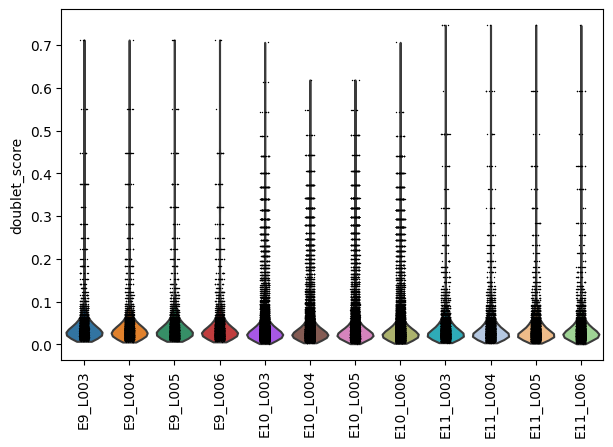

In [18]:
print(adata.var_names.is_unique)

sc.pl.violin(
    adata,
    "doublet_score",
    groupby="plate",
    rotation=90
)

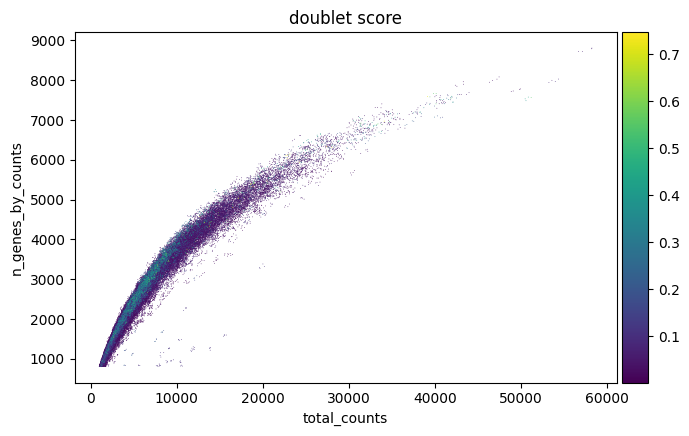

In [19]:
sc.pl.scatter(
    adata,
    x="total_counts",
    y="n_genes_by_counts",
    color="doublet_score"
)

In [20]:
adata.obs.groupby(
    ["plate", "predicted_doublet"],
    observed=True
)[
    ["n_genes_by_counts", "total_counts", "doublet_score"]
].median()

n_genes_by_counts  total_counts  doublet_score
plate    predicted_doublet                                                
E9_L003  False                         4015.0       11771.5       0.030842
         True                          6107.0       24968.0       0.550296
E9_L004  False                         4045.0       11956.5       0.030842
         True                          6886.0       33364.0       0.550296
E9_L005  False                         4068.0       11988.0       0.030842
         True                          6643.0       31057.5       0.550296
E9_L006  False                         4034.0       11823.0       0.030842
         True                          5753.5       21659.5       0.712121
E10_L003 False                         1736.0        3197.0       0.027027
         True                          2875.0        6280.0       0.293919
E10_L004 False                         1753.0        3238.0       0.026726
         True                          2897.5        6333.5       0.278481
E10_L005 False                         1761.0        3259.0       0.026178
         True                          2904.0        6414.0       0.297479
E10_L006 False                         1743.0        3214.0       0.026464
         True                          2873.0        6276.0       0.293919
E11_L003 False                         2684.0        6309.0       0.027949
         True                          4805.0       15517.5       0.746667
E11_L004 False                         2707.5        6396.0       0.027002
         True                          4818.0       16618.5       0.593583
E11_L005 False                         2715.0        6443.0       0.027002
         True                          4444.0       14896.0       0.593583
E11_L006 False                         2697.5        6337.5       0.027949
         True                          4412.0       13851.0       0.593583

In [21]:
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30]

rows = []

for plate in adata.obs["plate"].unique():
    x = adata.obs.loc[adata.obs["plate"] == plate, "doublet_score"]

    row = {"plate": plate}

    for t in thresholds:
        row[f">{t}"] = 100 * (x > t).mean()

    rows.append(row)

pd.DataFrame(rows).set_index("plate")

,>0.1,>0.15,>0.2,>0.25,>0.3
plate,,,,,
E9_L003,4.998712,2.834321,2.035558,1.339861,1.030662
E9_L004,5.107042,3.043590,2.192417,1.392830,1.083312
E9_L005,5.058065,2.761290,2.116129,1.316129,1.109677
E9_L006,5.293054,2.969274,2.297960,1.394268,1.084431
E10_L003,8.401694,5.755491,4.293464,3.135750,1.812649
E10_L004,8.408746,5.733536,4.135016,2.767686,1.677786
E10_L005,8.057592,5.461991,3.909913,2.892808,1.624728
E10_L006,8.357025,5.712397,4.238017,3.008264,1.679339
E11_L003,3.974476,2.023701,1.294439,0.984503,0.747493


In [22]:
adata.obs["doublet_020"] = adata.obs["doublet_score"] > 0.20

In [23]:
pd.crosstab(
    adata.obs["plate"],
    adata.obs["doublet_020"],
    normalize="index"
) * 100

doublet_020,False,True
plate,,
E9_L003,97.964442,2.035558
E9_L004,97.807583,2.192417
E9_L005,97.883871,2.116129
E9_L006,97.702040,2.297960
E10_L003,95.706536,4.293464
E10_L004,95.864984,4.135016
E10_L005,96.090087,3.909913
E10_L006,95.761983,4.238017
E11_L003,98.705561,1.294439


In [24]:
adata.obs.groupby(
    ["plate", "doublet_020"],
    observed=True
)[["n_genes_by_counts", "total_counts", "pct_counts_mt"]].median()

n_genes_by_counts  total_counts  pct_counts_mt
plate    doublet_020                                                
E9_L003  False                   3997.5       11683.5       2.374542
         True                    5820.0       22396.0       2.419604
E9_L004  False                   4029.5       11873.5       2.384855
         True                    5791.0       22261.0       2.279095
E9_L005  False                   4056.0       11914.0       2.353744
         True                    5405.5       19847.5       2.404520
E9_L006  False                   4010.5       11726.0       2.360477
         True                    5506.0       21190.0       2.434626
E10_L003 False                   1736.0        3197.0       1.662478
         True                    2875.0        6280.0       1.699190
E10_L004 False                   1754.0        3241.0       1.677341
         True                    2907.0        6351.5       1.676169
E10_L005 False                   1761.0        3259.0       1.667461
         True                    2904.0        6414.0       1.675755
E10_L006 False                   1739.0        3208.0       1.665567
         True                    2858.0        6226.0       1.677940
E11_L003 False                   2675.0        6283.0       1.525752
         True                    4076.0       11480.0       1.668362
E11_L004 False                   2699.5        6376.0       1.534979
         True                    4122.5       12138.0       1.551480
E11_L005 False                   2708.0        6409.0       1.530711
         True                    4117.0       11675.0       1.629348
E11_L006 False                   2692.0        6321.0       1.530023
         True                    3997.0       11248.5       1.596819

In [26]:
#adata.obs["doublet_020"] = adata.obs["doublet_score"] > 0.2

In [25]:
adata = adata[~adata.obs["doublet_020"]].copy()

In [26]:
print("Before:", adata.n_obs)
print("Doublets:", adata.obs["doublet_020"].sum())

adata = adata[~adata.obs["doublet_020"]].copy()

print("After:", adata.n_obs)

Before: 94890
Doublets: 0
After: 94890


In [27]:
adata_check = sc.concat(
    scrubbed,
    join="outer",
    merge="same"
)

adata_check.obs["doublet_020"] = adata_check.obs["doublet_score"] > 0.20

print("Before:", adata_check.n_obs)
print("Doublets:", adata_check.obs["doublet_020"].sum())
print("Percent:", 100 * adata_check.obs["doublet_020"].mean())
print("After:", (~adata_check.obs["doublet_020"]).sum())

Before: 98007
Doublets: 3117
Percent: 3.1803850745354927
After: 94890


In [28]:
adata = adata_check[~adata_check.obs["doublet_020"]].copy()

print(adata.n_obs)

94890


In [30]:
adata.layers["counts"] = adata.X.copy()
adata.write("/home/julia/data/placodes/ANDYs_notebboks/h5ad/" "E9_E10_E11_QC_SCRUBLET_020.h5ad")

In [2]:
adata=sc.read_h5ad( "/home/julia/data/placodes/ANDYs_notebboks/h5ad/E9_E10_E11_QC_SCRUBLET_020.h5ad")

In [3]:
# Normalize
sc.pp.normalize_total(adata, target_sum=1e4)

# Log-transform
sc.pp.log1p(adata)

normalizing counts per cell
    finished (0:00:01)


If you pass `n_top_genes`, all cutoffs are ignored.
extracting highly variable genes
--> added
    'highly_variable', boolean vector (adata.var)
    'highly_variable_rank', float vector (adata.var)
    'means', float vector (adata.var)
    'variances', float vector (adata.var)
    'variances_norm', float vector (adata.var)
HVGs: 3000


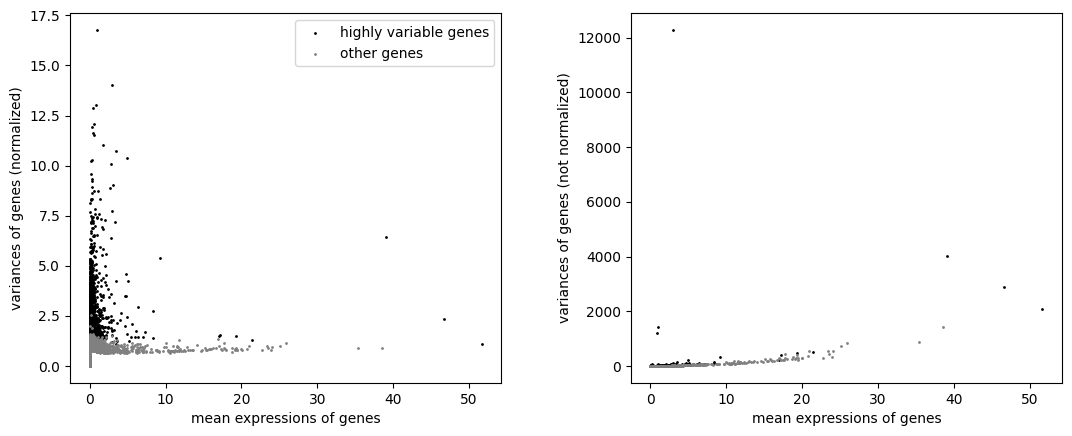

In [4]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=3000,
    flavor="seurat_v3",
    batch_key="plate",
    layer="counts"
)

print("HVGs:", adata.var["highly_variable"].sum())

sc.pl.highly_variable_genes(adata)

In [5]:
sc.tl.pca(
    adata,
    n_comps=70,
    use_highly_variable=True
)

computing PCA
    on highly variable genes
    with n_comps=70
    finished (0:00:38)


In [6]:
print(adata.shape)
print(adata.obs["day"].value_counts())
print(adata.obs["plate"].value_counts())

(94890, 32285)
E10    58013
E11    21706
E9     15171
Name: day, dtype: int64
E10_L005    14549
E10_L004    14513
E10_L006    14484
E10_L003    14467
E11_L004     5436
E11_L005     5431
E11_L006     5425
E11_L003     5414
E9_L003      3802
E9_L005      3793
E9_L004      3792
E9_L006      3784
Name: plate, dtype: int64


computing neighbors
    using 'X_pca' with n_pcs = 69
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:06:47)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:03:37)
running Leiden clustering
    finished: found 19 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:59)


/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


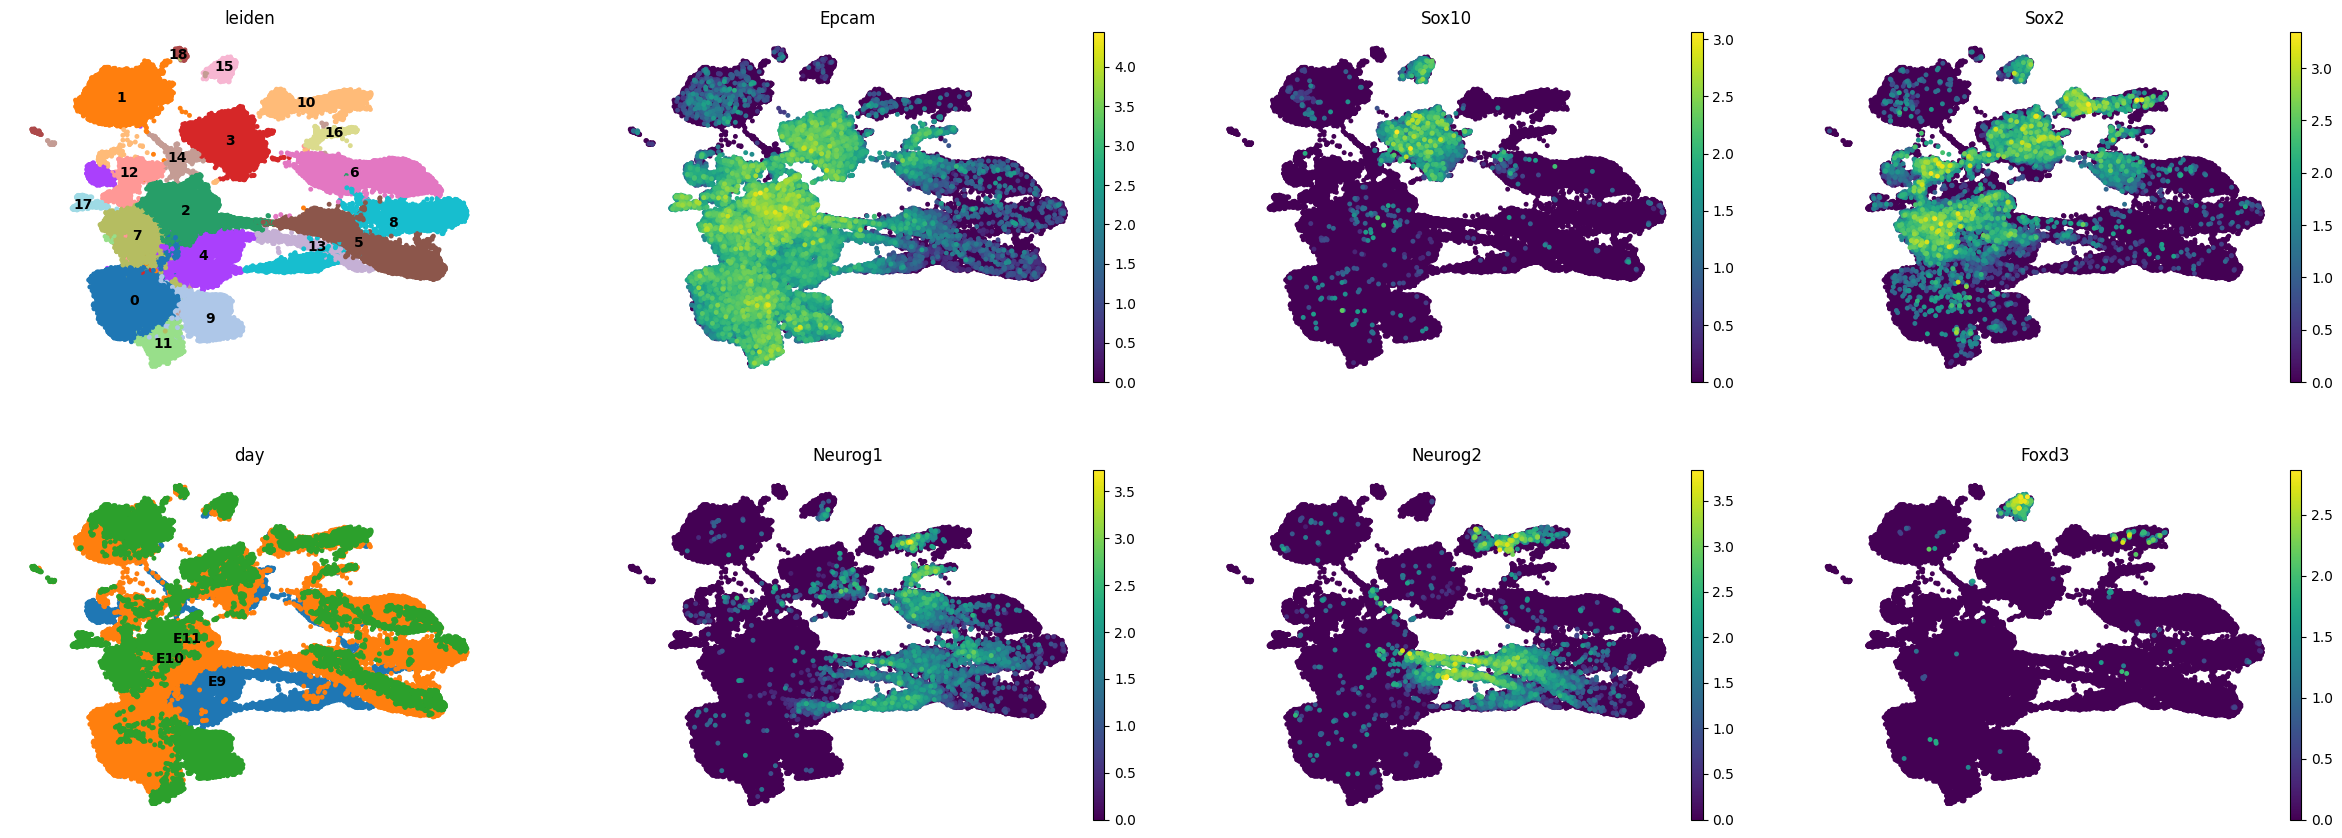

In [7]:
sc.pp.neighbors(adata, n_neighbors=60, n_pcs=69)
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.5)
sc.pl.umap(adata, color=['leiden',  'Epcam','Sox10', 'Sox2', 'day','Neurog1', 'Neurog2', 'Foxd3' ], size=50, frameon=False, legend_loc='on data')

/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


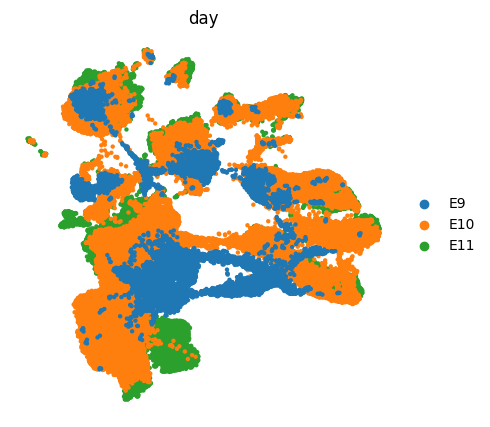

In [20]:
import matplotlib.pyplot as plt
list(set(adata.obs.day))
ig, ax = plt.subplots(figsize=(5, 5))
 
s = 120000 / len(adata) * 4
sc.pl.umap(adata, color="day", frameon=False, ax=ax, show=False, s=s)
 
groups = ['E11','E10', 'E9']
for group in groups:
     sc.pl.umap(adata[adata.obs.day == group], color="day", frameon=False, ax=ax, show=False,legend_loc=None, size=40, )

In [21]:
adata.write(
    "/home/julia/data/placodes/ANDYs_notebboks/h5ad/"
    "E9_E10_E11_UMAP.h5ad")